# AAI-521 Applied Computer Vision for AI
## Final Project: Old Photo Restoration Studio
### Notebook 03 &mdash; Photo Repair: Damage Detection, Tone Correction and Inpainting

**Student Name:** Diaesh Antony
**Course:** AAI-521: Applied Computer Vision for AI
**Degree Program:** Master of Science in Applied Artificial Intelligence (MS-AAI)
**University:** University of San Diego, Shiley-Marcos School of Engineering
**Instructor:** Rajesh Soni, M.S.

---

## Overview

This notebook is the repair step of the restoration pipeline. It takes a damaged photo, finds the damage, repairs it, and passes the repaired photo on to colorization (notebook 04). It starts from the U-Net damage detector of notebook 02.

**Research question.** Does a pretrained deep restoration model, adapted to realistic photo damage, repair old photos measurably better than classical image processing? And where does the remaining error come from?

### Methods compared

| Method | What it does | Training |
|---|---|---|
| **Unrepaired input** | The damaged photo, unchanged. Every method must beat this. | &ndash; |
| **Classical (inpaint + denoise + contrast)** | OpenCV Telea inpainting inside the mask, then Non-Local Means denoising and CLAHE contrast enhancement on the whole photo. | none |
| **Classical, masked pixels only** | OpenCV Telea inpainting inside the mask; every other pixel is left untouched. | none |
| **Pretrained Wan et al. (2020)** | Microsoft's *Bringing Old Photos Back to Life* scratch-restoration network with its published weights: two variational autoencoders and a latent mapping network with partial non-local attention. | none (published weights) |
| **Fine-tuned Wan et al.** | The same network with both autoencoders frozen and only the latent mapping network fine-tuned on OpenPhoto Restore. | 3 random seeds |
| **Full pipeline (ours)** | Three steps: an OpenPhoto-adapted damage detector finds the damage; a learned tone correction removes fading and colour casts from the whole photo; LaMa, a pretrained large-mask inpainting network, fills the detected damage. | detector and tone network trained here; LaMa pretrained |

The full pipeline was developed after the first study showed where the remaining error comes from: the original detector found only a small share of the damage, and most of the error was a change of tone across the whole photo rather than local defects. Sections 8 to 10 build its three components one at a time.

### Evaluation protocol

* **Data.** OpenPhoto Restore (Hugging Face `joshuachin/openphoto-restore-dataset`): pairs of a damaged photo and its clean original. The official test split (497 usable pairs) is held out and used once, for the final results. The official training split is divided into training (4,050) and validation (450) photos. No photo appears in more than one split; this is checked in code.
* **Masks.** Sections 6 and 7 use the masks of the damage detector from notebook 02, exactly as delivered. Section 8 adapts a copy of that detector to OpenPhoto, and Section 10 re-scores the earlier methods with the adapted masks, so every method can be compared with the same masks.
* **Reference damage masks.** OpenPhoto ships no masks, so Section 3 derives a reference mask from each damaged photo and its clean original. They are used to train the adapted detector, to measure how much damage a detector finds, and to measure repair quality on the damaged pixels. They need the clean original, so the application never uses them.
* **Metrics.** PSNR, SSIM and LPIPS (AlexNet) on luminance, plus PSNR inside the reference damage mask and the median runtime per photo. Luminance is used because OpenPhoto's damage removes colour, and restoring colour is the job of the colorization notebook. RGB PSNR is reported for reference.
* **Fair comparison.** Some methods change every pixel and others only masked pixels. Whole-photo metrics capture both kinds of change; PSNR inside the reference damage compares all methods on the same damaged pixels, whichever mask they were given.

All model, data and metric code is imported from the project's `src/` package (`src/repair.py`, `src/tone.py`, `src/inpaint.py`, `src/reference_masks.py`, `src/detector_finetune.py`, `src/metrics.py`, `src/data/openphoto.py`, `src/damage_detection.py`).

## 1. Setup

This section prepares the environment:

* installs the few packages Colab does not ship with (`lpips` for the perceptual metric, `datasets` for Hugging Face downloads);
* fixes the random seeds so every run gives the same splits, crops and initialisations;
* locates the project repository (cloned from GitHub when running in Colab) and imports every model, data loader and metric from `src/`, so nothing is redefined in the notebook;
* mounts Google Drive and copies every result file there, because Colab can recycle the virtual machine during a long run.

In [1]:
!pip install -q lpips datasets opencv-python-headless scikit-image matplotlib tqdm pandas

In [13]:
import os, sys, time, random, subprocess, copy, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

SEEDS = [42, 123, 999]  # every trained model is trained once per seed

def set_seed(seed: int) -> None:
    # Seeds Python, NumPy and PyTorch (CPU and GPU) so a run can be repeated exactly.
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# TF32 matrix maths: faster on L4/A100 GPUs with no measurable effect on the metrics.
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# In Colab the project is cloned from GitHub; locally the notebook runs inside the repository.
REPO_URL = "https://github.com/diaeshantony-usd/old-photo-restoration-studio.git"
if IN_COLAB:
    BASE_DIR = Path("/content/old-photo-restoration-studio")
    if not BASE_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(BASE_DIR)], check=True)
    WORK_DIR = Path("/content/work")
else:
    BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "repair.py").exists())
    WORK_DIR = BASE_DIR / "data" / "work"
sys.path.insert(0, str(BASE_DIR))

# Output folders: model checkpoints, figures and result tables.
MODELS_DIR = BASE_DIR / "models"
FIG_DIR = BASE_DIR / "results" / "figures"
TAB_DIR = BASE_DIR / "results" / "tables"
for d in (WORK_DIR, MODELS_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Project code: detector (notebook 02), data loading, metrics, repair models and tone correction.
from src.damage_detection import DamageDetector
from src.data.openphoto import (load_openphoto_split, subset, train_val_rows, check_disjoint,
                                OpenPhotoRepairDataset)
from src.metrics import LPIPSMetric, luma_rgb_u8, masked_psnr_y, psnr_rgb, psnr_y, ssim_y, to_luma
from src.repair import (OpenCVBaselineRestorer, WanRestorer, finetune_wan_mapping,
                        load_mapping_weights, load_wan_scratch_model, save_mapping_weights,
                        setup_wan_repo)
from src.reference_masks import reference_mask, mask_scores, tone_fit, local_residual
from src.detector_finetune import finetune_detector, predict_masks as predict_masks_at
from src.tone import ToneCorrector, build_tone_dataset, train_tone_net, save_tone_net
from src.inpaint import LamaInpainter, TeleaInpainter, RepairPipeline
print(f"Repository: {BASE_DIR}")

Device: cuda (NVIDIA L4)
Repository: /content/old-photo-restoration-studio


In [3]:
# Colab virtual machines can be recycled during long runs, so every result file is also copied to Google Drive.
DRIVE_OUT = None
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_OUT = Path("/content/drive/MyDrive/old-photo-restoration-studio/s2_repair_outputs")
    DRIVE_OUT.mkdir(parents=True, exist_ok=True)

def save_to_drive(*paths):
    # Copies result files to the same relative path under DRIVE_OUT (does nothing outside Colab).
    if DRIVE_OUT is None:
        return
    for p in map(Path, paths):
        dst = DRIVE_OUT / p.relative_to(BASE_DIR)
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, dst)
        print(f"Saved to Drive: {dst.relative_to(DRIVE_OUT)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data

OpenPhoto Restore provides 5,000 photos, each as a pair: a synthetically damaged copy (scratches, cracks, dust, grain, fading, grayscale or sepia) and the clean original. Having the clean original is what makes it possible to measure repair quality objectively.

* Each photo is resized so its short side is 512 px and centre-cropped to 512 &times; 512; the damaged copy and the clean original get the same transform.
* The official training split is divided into training and validation photos with a fixed seed. The official test split is kept aside until the final evaluation.
* `check_disjoint` confirms that no photo appears in more than one split, so no test photo can influence training or model selection.
* Fine-tuning uses random 256 &times; 256 crops; evaluation uses the full 512 &times; 512 photos.

In [4]:
IMG_SIZE = 512
# Downloads OpenPhoto Restore once and caches the resized arrays on disk.
full_train = load_openphoto_split("train", size=IMG_SIZE, cache_dir=WORK_DIR / "hf")
test_set = load_openphoto_split("test", size=IMG_SIZE, cache_dir=WORK_DIR / "hf")
# 90% / 10% training / validation split of the official training photos, fixed by seed 42.
tr_rows, va_rows = train_val_rows(len(full_train), val_fraction=0.1, seed=42)
train_set, val_set = subset(full_train, tr_rows), subset(full_train, va_rows)
del full_train
check_disjoint(train_set, val_set, test_set)  # raises an error if any photo is in two splits

# Three test pairs are byte-identical (no damage was applied), so there is nothing to repair
# and PSNR is undefined. They are left out.
same = np.array([np.array_equal(a, b) for a, b in zip(test_set.damaged, test_set.pristine)])
test_set = subset(test_set, np.where(~same)[0])

# Summary of the three splits
pd.DataFrame({"Split": ["Training", "Validation", "Test"],
              "Photos": [len(train_set), len(val_set), len(test_set)],
              "Notes": ["used for fine-tuning", "used to choose the best epoch",
                        f"held out; {int(same.sum())} undamaged pairs removed"]})

,Split,Photos,Notes
0,Training,4050,used for fine-tuning
1,Validation,450,used to choose the best epoch
2,Test,497,held out; 3 undamaged pairs removed


## 3. Damage masks

Repair methods need to know where the damage is. Two kinds of mask are used in this notebook.

**Detector masks.** The U-Net detector trained in notebook 02 predicts one binary mask per photo (pixel probability above 0.5, then a 1-pixel dilation so thin scratches are fully covered). The same masks are used for fine-tuning and for every method in Sections 6 and 7, so all methods see exactly the same damage.

**Reference masks.** Because every damaged photo comes with its clean original, a reference damage mask can be derived from the pair (`src/reference_masks.py`):

1. For each colour channel, fit a tone curve that maps the damaged photo to the clean luminance. This removes fading and sepia that affect the whole photo.
2. Keep only local differences and take the largest over the three channels, so scratches that differ mainly in colour (for example a yellow scratch on a white sky) are found too.
3. Mark pixels that stand out from their own neighbourhood (thin scratches, dust) and large connected regions with a clear difference in smooth areas (long scratches, tears, cracks). Strongly textured areas are excluded unless the difference is very large, because blur alone changes texture.
4. Remove specks below 8 pixels and dilate by 2 pixels.

The second table measures how much of the reference damage the notebook-02 detector finds on OpenPhoto.

In [5]:
# Load the trained detector from notebook 02. Large photos are processed in overlapping 512 px tiles.
DETECTOR_CKPT = MODELS_DIR / "damage_detection_unet.pt"
assert DETECTOR_CKPT.exists(), "damage detector weights are missing"
detector = DamageDetector(checkpoint_path=DETECTOR_CKPT, device=str(DEVICE), tile_size=IMG_SIZE, overlap=64)

def predict_masks(arrays, desc):
    # One H x W uint8 mask per damaged photo (1 = damaged pixel).
    return np.stack([detector.predict(img) for img in tqdm(arrays.damaged, desc=desc)]).astype(np.uint8)

train_masks = predict_masks(train_set, "Training masks")
val_masks = predict_masks(val_set, "Validation masks")
test_masks = predict_masks(test_set, "Test masks")

def coverage_row(name, m):
    # Share of pixels marked as damaged, per photo, summarised over a split.
    cov = m.reshape(len(m), -1).mean(1) * 100
    return {"Split": name, "Mean coverage (%)": round(cov.mean(), 2), "Median coverage (%)": round(np.median(cov), 2),
            "Photos with empty mask (%)": round(np.mean(cov == 0) * 100, 1)}

pd.DataFrame([coverage_row("Training", train_masks), coverage_row("Validation", val_masks), coverage_row("Test", test_masks)])

Training masks:   0%|          | 0/4050 [00:00<?, ?it/s]

Validation masks:   0%|          | 0/450 [00:00<?, ?it/s]

Test masks:   0%|          | 0/497 [00:00<?, ?it/s]

,Split,Mean coverage (%),Median coverage (%),Photos with empty mask (%)
0,Training,0.59,0.08,28.5
1,Validation,0.57,0.06,28.7
2,Test,0.69,0.08,30.0


In [6]:
# Reference damage masks for every split (needs the clean original; analysis and training labels only).
ref_train = np.stack([reference_mask(d, c) for d, c in zip(tqdm(train_set.damaged, desc="Reference masks, training"), train_set.pristine)])
ref_val = np.stack([reference_mask(d, c) for d, c in zip(tqdm(val_set.damaged, desc="Reference masks, validation"), val_set.pristine)])
ref_test = np.stack([reference_mask(d, c) for d, c in zip(tqdm(test_set.damaged, desc="Reference masks, test"), test_set.pristine)])

rows = [coverage_row("Reference, training", ref_train), coverage_row("Reference, test", ref_test)]
display(pd.DataFrame(rows))

# How much of the reference damage does the notebook-02 detector find on the test photos?
recall, precision, iou = mask_scores(test_masks, ref_test)
pd.DataFrame([{"Detector": "Notebook 02 U-Net (as delivered)", "Recall": round(recall, 3), "Precision": round(precision, 3),
               "IoU": round(iou, 3)}]).set_index("Detector")

Reference masks, training:   0%|          | 0/4050 [00:00<?, ?it/s]

Reference masks, validation:   0%|          | 0/450 [00:00<?, ?it/s]

Reference masks, test:   0%|          | 0/497 [00:00<?, ?it/s]

,Split,Mean coverage (%),Median coverage (%),Photos with empty mask (%)
0,"Reference, training",3.80,2.79,11.6
1,"Reference, test",3.52,2.49,10.9


,Recall,Precision,IoU
Detector,,,
Notebook 02 U-Net (as delivered),0.039,0.201,0.034


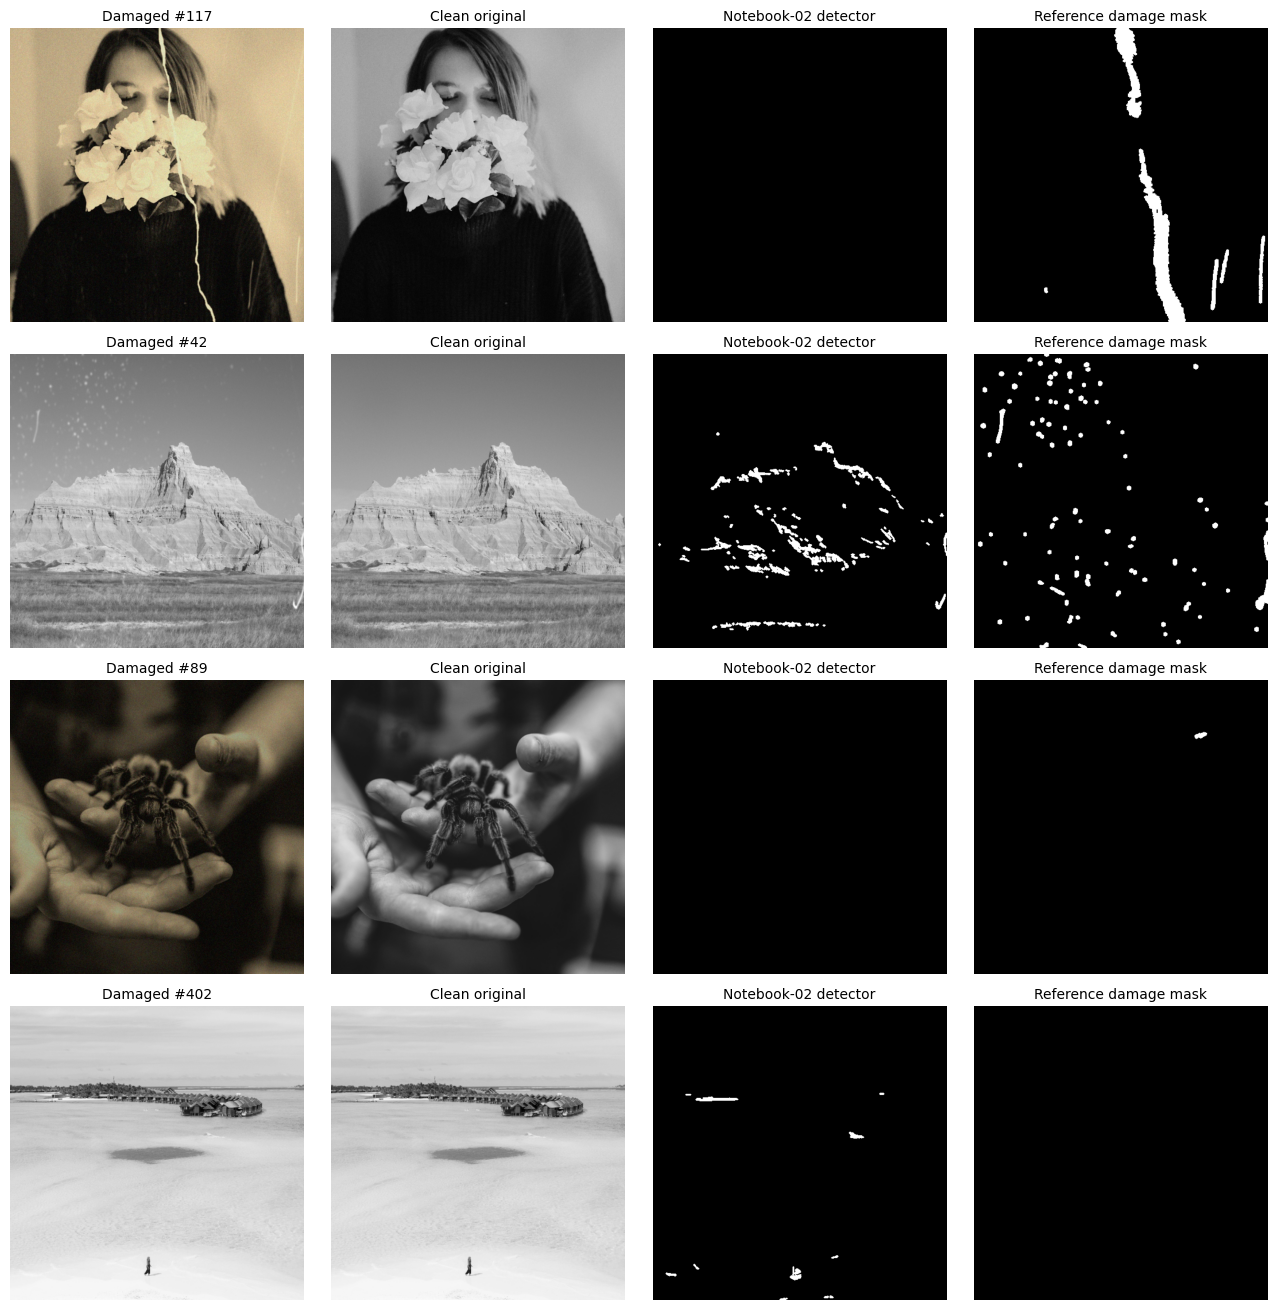

In [7]:
# Reference masks on four test photos: damaged photo, clean original, notebook-02 detector mask, reference mask.
show_idx = np.random.default_rng(3).choice(len(test_set), 4, replace=False)
fig, axes = plt.subplots(len(show_idx), 4, figsize=(13, 3.3 * len(show_idx)))
for r, i in enumerate(show_idx):
    for c, (im, title) in enumerate([(test_set.damaged[i], f"Damaged #{int(test_set.ids[i])}"), (luma_rgb_u8(test_set.pristine[i]), "Clean original"),
                                     (test_masks[i], "Notebook-02 detector"), (ref_test[i], "Reference damage mask")]):
        axes[r, c].imshow(im, cmap="gray"); axes[r, c].set_title(title, fontsize=10); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

## 4. Models

The deep model is Wan et al. (2020), *Bringing Old Photos Back to Life*. It works in three steps:

1. **Autoencoder A** encodes the damaged photo into a compact latent representation.
2. **The latent mapping network** translates that representation into the latent of a clean photo. Its partial non-local block uses the damage mask so that damaged regions are filled from similar undamaged regions elsewhere in the photo.
3. **Autoencoder B** decodes the clean latent back into an image.

`setup_wan_repo` downloads Microsoft's code and published checkpoints (release v1.0), and `load_wan_scratch_model` builds the network with the same options as Microsoft's own `test.py`. Both autoencoders are frozen: they already know how to represent photos, and freezing them lets the 51 M-parameter mapping network adapt to OpenPhoto's damage with a few thousand training photos.

The classical baselines come from OpenCV and need no training.

In [8]:
# Download Microsoft's code and checkpoints, build the network and keep a copy of the published mapping weights.
WAN_GLOBAL = setup_wan_repo(WORK_DIR / "Bringing-Old-Photos-Back-to-Life")
wan_model = load_wan_scratch_model(WAN_GLOBAL, DEVICE)
PUBLISHED_MAPPING = copy.deepcopy(wan_model.mapping_net.state_dict())
# Both autoencoders must be frozen; only the mapping network is trainable.
assert not any(p.requires_grad for p in wan_model.netG_A.parameters())
assert not any(p.requires_grad for p in wan_model.netG_B.parameters())

# Size of each component, in millions of parameters
n_params = lambda net: sum(p.numel() for p in net.parameters()) / 1e6
display(pd.DataFrame({
    "Component": ["Autoencoder A (degraded photos)", "Autoencoder B (clean photos)", "Latent mapping network"],
    "Parameters (M)": [round(n_params(wan_model.netG_A), 2), round(n_params(wan_model.netG_B), 2), round(n_params(wan_model.mapping_net), 2)],
    "Fine-tuned": ["no (frozen)", "no (frozen)", "yes"]}))

# Display names used in every table and figure
INPUT = "Unrepaired input"
CLASSICAL = "Classical (inpaint + denoise + contrast)"
CLASSICAL_MASKED = "Classical, masked pixels only"
PRETRAINED = "Pretrained Wan et al. (2020)"
FINETUNED = "Fine-tuned Wan et al."
TONE = "Learned tone correction"
FULL = "Full pipeline (ours)"

# Restorers: each exposes restore(damaged_rgb, mask) -> repaired_rgb
classical = OpenCVBaselineRestorer(mask_only=False)
classical_masked = OpenCVBaselineRestorer(mask_only=True)
pretrained = WanRestorer(wan_model, mode="pretrained", device=DEVICE)

You are using NL + Res


,Component,Parameters (M),Fine-tuned
0,Autoencoder A (degraded photos),0.87,no (frozen)
1,Autoencoder B (clean photos),0.87,no (frozen)
2,Latent mapping network,51.34,yes


## 5. Evaluation helpers

Every method is scored the same way, against the clean original photo:

* **PSNR** (dB, higher is better): pixel-level fidelity.
* **SSIM** (0 to 1, higher is better): agreement of local structure and contrast.
* **LPIPS** (lower is better): perceptual distance measured with a pretrained AlexNet; it tracks how different two images look to people.
* **PSNR inside the damage:** fidelity on the pixels of the reference damage mask only, the same pixels for every method.
* **Runtime:** milliseconds per photo.

`evaluate` returns one row per photo, and `summarize` averages those rows for the results table. The two photos used in the visual comparison are fixed here, by a seeded rule, before any model is run.

In [9]:
lpips_metric = LPIPSMetric(DEVICE)

def evaluate(restore_fn, arrays, masks, desc, keep=()):
    # Runs restore_fn(damaged, mask) on every test photo, scores it against the clean original and keeps
    # the outputs of the photos listed in `keep`. PSNR inside the damage uses the reference masks.
    rows, outputs = [], {}
    for i in tqdm(range(len(arrays)), desc=desc, leave=False):
        damaged, clean, mask = arrays.damaged[i], arrays.pristine[i], masks[i]
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()  # wait for earlier GPU work so the timing covers this photo only
        t0 = time.perf_counter()
        out = restore_fn(damaged, mask)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        rows.append({"id": int(arrays.ids[i]), "psnr_y": psnr_y(out, clean), "ssim_y": ssim_y(out, clean),
                     "lpips_y": lpips_metric(out, clean), "masked_psnr_y": masked_psnr_y(out, clean, ref_test[i]),
                     "psnr_rgb": psnr_rgb(out, clean), "runtime_ms": (time.perf_counter() - t0) * 1000})
        if i in keep:
            outputs[i] = out
    return pd.DataFrame(rows), outputs

def summarize(df):
    # Mean of each metric over photos (median for runtime). PSNR inside the damage skips photos without damage.
    return {"psnr_y": df.psnr_y.mean(), "ssim_y": df.ssim_y.mean(), "lpips_y": df.lpips_y.mean(),
            "masked_psnr_y": np.nanmean(df.masked_psnr_y), "psnr_rgb": df.psnr_rgb.mean(),
            "runtime_ms": df.runtime_ms.median()}

def show_line(name, s):
    # One-line progress summary printed after each method.
    print(f"{name:42s} PSNR {s['psnr_y']:6.2f} dB | SSIM {s['ssim_y']:.4f} | LPIPS {s['lpips_y']:.4f} | "
          f"PSNR in damage {s['masked_psnr_y']:6.2f} dB | {s['runtime_ms']:6.1f} ms")

# Two photos for the visual comparison, chosen by a fixed rule before any model is run:
# a seeded draw among test photos whose detector mask covers 2-15% of the image.
cov = test_masks.reshape(len(test_masks), -1).mean(1)
eligible = np.where((cov > 0.02) & (cov < 0.15))[0]
FIG_IDX = sorted(np.random.default_rng(7).choice(eligible, size=2, replace=False).tolist())
print(f"Photos for the visual comparison: test #{int(test_set.ids[FIG_IDX[0]])} and #{int(test_set.ids[FIG_IDX[1]])}")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Photos for the visual comparison: test #303 and #476


## 6. Baselines: classical and pretrained

These methods need no training on OpenPhoto, so they show what is achievable out of the box. They use the notebook-02 detector masks.

* **Unrepaired input** is the reference point: a method that scores below it makes photos worse.
* **Classical** repair inpaints the masked pixels, then denoises and boosts contrast across the whole photo.
* **Classical, masked pixels only** inpaints the masked pixels and leaves everything else untouched.
* **Pretrained Wan et al.** runs Microsoft's published model unchanged.

In [10]:
# results: per-method summaries | fig_outputs: outputs for the figure photos | per_image: per-photo scores
results, fig_outputs, per_image = {}, {}, {}
for name, fn in [(INPUT, lambda img, m: img.copy()),
                 (CLASSICAL, classical.restore),
                 (CLASSICAL_MASKED, classical_masked.restore),
                 (PRETRAINED, pretrained.restore)]:
    df, outs = evaluate(fn, test_set, test_masks, name, keep=set(FIG_IDX))
    results[name], fig_outputs[name], per_image[name] = [summarize(df)], outs, df
    show_line(name, results[name][0])

Unrepaired input:   0%|          | 0/497 [00:00<?, ?it/s]

Unrepaired input                           PSNR  21.65 dB | SSIM 0.8551 | LPIPS 0.1719 | PSNR in damage  16.73 dB |   64.6 ms


Classical (inpaint + denoise + contrast):   0%|          | 0/497 [00:00<?, ?it/s]

Classical (inpaint + denoise + contrast)   PSNR  20.12 dB | SSIM 0.8248 | LPIPS 0.2253 | PSNR in damage  16.00 dB |  443.9 ms


Classical, masked pixels only:   0%|          | 0/497 [00:00<?, ?it/s]

Classical, masked pixels only              PSNR  21.31 dB | SSIM 0.8524 | LPIPS 0.1750 | PSNR in damage  16.84 dB |   81.4 ms


Pretrained Wan et al. (2020):   0%|          | 0/497 [00:00<?, ?it/s]

Pretrained Wan et al. (2020)               PSNR  21.76 dB | SSIM 0.8058 | LPIPS 0.2092 | PSNR in damage  17.06 dB |  232.7 ms


## 7. Fine-tuning the mapping network

Only the latent mapping network is trained; both autoencoders stay at Microsoft's published weights.

* **Loss.** `60 × L1(mapped latent, latent of the clean photo)` + `10 × L1(output image, clean photo)`. This follows Microsoft's training recipe without the adversarial and perceptual terms, to fit a single Colab session.
* **Optimiser.** Adam, learning rate 1e-4, batch size 8, 5 epochs per seed.
* **Model selection.** Each seed starts from the published weights. The epoch with the best masked PSNR on the first 100 validation photos is kept. The test set is never used for any choice.
* **Seeds.** 42, 123 and 999. The results table reports mean &plusmn; standard deviation over the three seeds; the seed with the best validation score is saved as the shipped checkpoint.

In [11]:
EPOCHS, BATCH, VAL_N = 5, 8, 100   # epochs per seed, crops per batch, validation photos used for model selection

# Training data: random 256 x 256 crops of damaged photos with their masks and clean originals.

train_ds = OpenPhotoRepairDataset(train_set, train_masks, crop_size=256, is_training=True)
val_small = subset(val_set, np.arange(VAL_N))
val_small_masks = val_masks[:VAL_N]

def val_masked_psnr():
    # Model-selection score: mean PSNR inside the detector mask on the first VAL_N validation photos.
    r = WanRestorer(wan_model, mode="validation", device=DEVICE)
    return float(np.nanmean([masked_psnr_y(r.restore(val_small.damaged[i], val_small_masks[i]),
                                           val_small.pristine[i], val_small_masks[i]) for i in range(VAL_N)]))

finetune_runs = []
for seed in SEEDS:
    set_seed(seed)
    wan_model.mapping_net.load_state_dict(PUBLISHED_MAPPING)  # every seed starts from the published weights
    loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=4, pin_memory=True, drop_last=True,
                        generator=torch.Generator().manual_seed(seed), worker_init_fn=lambda w: np.random.seed(seed + w))
    # Trains the mapping network and returns the weights of the epoch with the best validation score.
    fit = finetune_wan_mapping(wan_model, loader, epochs=EPOCHS, seed=seed, val_fn=val_masked_psnr, device=DEVICE)
    # Score this seed on the held-out test set.
    model_seed = WanRestorer(wan_model, mode=f"fine_tuned_seed{seed}", device=DEVICE)
    df, outs = evaluate(model_seed.restore, test_set, test_masks, f"Fine-tuned, seed {seed}", keep=set(FIG_IDX))
    per_image[f"Fine-tuned, seed {seed}"] = df
    finetune_runs.append({"seed": seed, "summary": summarize(df), "best_val": fit["best_val"],
                          "history": fit["history"], "state": copy.deepcopy(fit["state_dict"]), "fig": outs})
    print(f"Seed {seed}: best validation masked PSNR {fit['best_val']:.2f} dB")
    show_line(f"  test set, seed {seed}", finetune_runs[-1]["summary"])

# Ship the seed with the best validation score (never chosen by test score).
# The weights are saved in fp16 and split into two files, each below GitHub's 100 MB limit.
best = max(finetune_runs, key=lambda r: r["best_val"])
CKPT = MODELS_DIR / "repair_wan_mapping_finetuned.pt"
shards = save_mapping_weights(best["state"], CKPT, meta={"seed": best["seed"], "epochs": EPOCHS,
                              "best_val_masked_psnr_y": best["best_val"],
                              "base": "microsoft/Bringing-Old-Photos-Back-to-Life v1.0 mapping_scratch"})
print(f"Shipped checkpoint: seed {best['seed']}, saved as " + " + ".join(f"{p.name} ({p.stat().st_size / 1e6:.1f} MB)" for p in shards))
save_to_drive(*shards)
results[FINETUNED] = [r["summary"] for r in finetune_runs]
fig_outputs[FINETUNED] = best["fig"]

  [seed 42] epoch 0 (published weights) | val 19.885
  [seed 42] epoch 1/5 | train loss 27.2174 | val 20.917 | 379s
  [seed 42] epoch 2/5 | train loss 26.6656 | val 21.088 | 375s
  [seed 42] epoch 3/5 | train loss 26.4204 | val 21.534 | 375s
  [seed 42] epoch 4/5 | train loss 26.3259 | val 21.900 | 375s
  [seed 42] epoch 5/5 | train loss 26.2187 | val 20.866 | 375s


Fine-tuned, seed 42:   0%|          | 0/497 [00:00<?, ?it/s]

Seed 42: best validation masked PSNR 21.90 dB
  test set, seed 42                        PSNR  23.95 dB | SSIM 0.8253 | LPIPS 0.1995 | PSNR in damage  20.56 dB |  233.8 ms
  [seed 123] epoch 0 (published weights) | val 19.885
  [seed 123] epoch 1/5 | train loss 27.2409 | val 21.132 | 375s
  [seed 123] epoch 2/5 | train loss 26.6553 | val 21.736 | 375s
  [seed 123] epoch 3/5 | train loss 26.4939 | val 21.424 | 375s
  [seed 123] epoch 4/5 | train loss 26.2779 | val 21.706 | 375s
  [seed 123] epoch 5/5 | train loss 26.3056 | val 22.302 | 375s


Fine-tuned, seed 123:   0%|          | 0/497 [00:00<?, ?it/s]

Seed 123: best validation masked PSNR 22.30 dB
  test set, seed 123                       PSNR  23.85 dB | SSIM 0.8315 | LPIPS 0.1949 | PSNR in damage  20.56 dB |  233.0 ms
  [seed 999] epoch 0 (published weights) | val 19.885
  [seed 999] epoch 1/5 | train loss 27.1900 | val 20.088 | 375s
  [seed 999] epoch 2/5 | train loss 26.6934 | val 20.907 | 375s
  [seed 999] epoch 3/5 | train loss 26.4471 | val 20.659 | 375s
  [seed 999] epoch 4/5 | train loss 26.3237 | val 21.740 | 375s
  [seed 999] epoch 5/5 | train loss 26.1706 | val 21.593 | 375s


Fine-tuned, seed 999:   0%|          | 0/497 [00:00<?, ?it/s]

Seed 999: best validation masked PSNR 21.74 dB
  test set, seed 999                       PSNR  23.88 dB | SSIM 0.8260 | LPIPS 0.2005 | PSNR in damage  20.67 dB |  233.8 ms
Shipped checkpoint: seed 123, saved as repair_wan_mapping_finetuned.part1of2.pt (85.5 MB) + repair_wan_mapping_finetuned.part2of2.pt (17.3 MB)
Saved to Drive: models/repair_wan_mapping_finetuned.part1of2.pt
Saved to Drive: models/repair_wan_mapping_finetuned.part2of2.pt


## 8. OpenPhoto-adapted damage detector

Section 3 shows that the notebook-02 detector, trained on a different kind of damage, finds only a small share of OpenPhoto's damage. A missed scratch can never be repaired, so the detector is adapted to this data:

* **Starting point.** A copy of the notebook-02 U-Net and its trained weights (`models/damage_detection_unet.pt`). Notebook 02 and its checkpoint are not changed.
* **Labels.** The reference damage masks of the training photos (Section 3).
* **Training.** Random 256 &times; 256 crops with flips, weighted binary cross-entropy plus Dice loss (damage pixels are rare), AdamW with a one-cycle learning-rate schedule, 12 epochs. The epoch with the best IoU on 150 validation photos is kept.
* **Threshold.** The pixel-probability threshold is chosen on the validation photos (highest IoU). The test photos are not used for any choice.
* **Output.** `models/damage_detection_unet_openphoto.pt`, loaded with the same `DamageDetector` class as notebook 02.

In [14]:
# Fine-tune a copy of the notebook-02 detector on OpenPhoto with the reference masks as labels.
VAL_DET = np.arange(150)
det_model, det_info = finetune_detector(DETECTOR_CKPT, train_set.damaged, ref_train,
                                        val_set.damaged[VAL_DET], ref_val[VAL_DET], DEVICE, epochs=12, seed=0)

# Choose the probability threshold on the validation photos.
sweep = []
for thr in [0.4, 0.5, 0.6, 0.7]:
    r, p, iou = mask_scores(predict_masks_at(det_model, val_set.damaged[VAL_DET], DEVICE, thr), ref_val[VAL_DET])
    sweep.append({"Threshold": thr, "Recall": round(r, 3), "Precision": round(p, 3), "IoU": round(iou, 3)})
sweep = pd.DataFrame(sweep)
DET_THRESHOLD = float(sweep.loc[sweep.IoU.idxmax(), "Threshold"])
display(sweep.set_index("Threshold"))
print(f"Best epoch {det_info['best_epoch']}; chosen threshold {DET_THRESHOLD}")

# Save under its own name and load it through the standard detector interface.
ADAPTED_CKPT = MODELS_DIR / "damage_detection_unet_openphoto.pt"
torch.save(det_model.state_dict(), ADAPTED_CKPT)
save_to_drive(ADAPTED_CKPT)
adapted_detector = DamageDetector(checkpoint_path=ADAPTED_CKPT, device=str(DEVICE), threshold=DET_THRESHOLD,
                                  tile_size=IMG_SIZE, overlap=64)
adapted_masks = predict_masks_at(det_model, test_set.damaged, DEVICE, DET_THRESHOLD)

# Test set: notebook-02 detector vs adapted detector, both against the reference damage masks.
rows = []
for name, m in [("Notebook 02 U-Net (as delivered)", test_masks), ("OpenPhoto-adapted U-Net", adapted_masks)]:
    r, p, iou = mask_scores(m, ref_test)
    rows.append({"Detector": name, "Recall": round(r, 3), "Precision": round(p, 3), "IoU": round(iou, 3),
                 "Mean coverage (%)": round(m.mean() * 100, 2)})
pd.DataFrame(rows).set_index("Detector")

Epoch  1: loss 1.519 | validation recall 0.703 precision 0.320 IoU 0.282 | 94 s
Epoch  2: loss 1.285 | validation recall 0.770 precision 0.259 IoU 0.241 | 188 s
Epoch  3: loss 1.246 | validation recall 0.762 precision 0.353 IoU 0.318 | 282 s
Epoch  4: loss 1.181 | validation recall 0.743 precision 0.315 IoU 0.284 | 377 s
Epoch  5: loss 1.166 | validation recall 0.762 precision 0.338 IoU 0.305 | 471 s
Epoch  6: loss 1.129 | validation recall 0.819 precision 0.324 IoU 0.302 | 565 s
Epoch  7: loss 1.094 | validation recall 0.825 precision 0.350 IoU 0.326 | 659 s
Epoch  8: loss 1.061 | validation recall 0.853 precision 0.351 IoU 0.331 | 753 s
Epoch  9: loss 1.028 | validation recall 0.849 precision 0.379 IoU 0.355 | 847 s
Epoch 10: loss 0.993 | validation recall 0.862 precision 0.415 IoU 0.390 | 940 s
Epoch 11: loss 0.965 | validation recall 0.871 precision 0.428 IoU 0.402 | 1034 s
Epoch 12: loss 0.950 | validation recall 0.854 precision 0.466 IoU 0.432 | 1128 s


,Recall,Precision,IoU
Threshold,,,
0.4,0.873,0.427,0.402
0.5,0.854,0.466,0.432
0.6,0.831,0.506,0.459
0.7,0.801,0.551,0.484


Best epoch 12; chosen threshold 0.7
Saved to Drive: models/damage_detection_unet_openphoto.pt


,Recall,Precision,IoU,Mean coverage (%)
Detector,,,,
Notebook 02 U-Net (as delivered),0.039,0.201,0.034,0.69
OpenPhoto-adapted U-Net,0.780,0.547,0.474,5.02


## 9. Learned tone correction

Most of OpenPhoto's damage is not local. Fading, contrast loss and sepia or colour casts change the tone of the whole photo, and Section 15 shows that one well-chosen brightness curve per photo removes far more error than perfect scratch repair. A fixed contrast stretch does not work, because each photo needs a different curve, so the curve is predicted by a small network (`src/tone.py`, 0.6 M parameters):

* **Inputs.** 128 &times; 128 thumbnails of the damaged photo's luminance and colour saturation, plus their histograms. Saturation tells the network how strongly a photo has been faded or toned; a photo that still has its colours is close to the original and needs little correction.
* **Output.** A monotone 16-segment brightness curve, applied to the full-resolution luminance. It only remaps brightness, so it cannot invent or move details.
* **Training.** L1 loss against the clean original, AdamW (learning rate 1e-3, cosine schedule), batch size 64, 40 epochs, horizontal flips. The epoch with the best validation PSNR is kept. Three seeds are trained; the seed with the best validation score is shipped.

In [15]:
# Training and validation data: thumbnails of each damaged photo and its clean luminance.
tone_train = build_tone_dataset(train_set.damaged, train_set.pristine)
tone_val = build_tone_dataset(val_set.damaged, val_set.pristine)

tone_runs = []
for seed in SEEDS:
    net, info = train_tone_net(tone_train, tone_val, epochs=40, seed=seed, device=DEVICE, log=None)
    corrector = ToneCorrector(net, device=DEVICE)
    df, outs = evaluate(lambda img, m: corrector(img), test_set, test_masks, f"Tone correction, seed {seed}", keep=set(FIG_IDX))
    per_image[f"Tone correction, seed {seed}"] = df
    tone_runs.append({"seed": seed, "net": net, "best_val": info["best_val_psnr"], "summary": summarize(df)})
    print(f"Seed {seed}: best validation PSNR {info['best_val_psnr']:.2f} dB (epoch {info['best_epoch']})")
    show_line(f"  test set, seed {seed}", tone_runs[-1]["summary"])
results[TONE] = [r["summary"] for r in tone_runs]

# Ship the seed with the best validation score.
best_tone = max(tone_runs, key=lambda r: r["best_val"])
TONE_CKPT = MODELS_DIR / "repair_tone_curve.pt"
save_tone_net(best_tone["net"], TONE_CKPT, {"seed": best_tone["seed"], "best_val_psnr": best_tone["best_val"],
                                            "inputs": "damaged luminance + saturation"})
save_to_drive(TONE_CKPT)
tone = ToneCorrector(best_tone["net"], device=DEVICE)
print(f"Shipped tone network: seed {best_tone['seed']}")

Tone correction, seed 42:   0%|          | 0/497 [00:00<?, ?it/s]

Seed 42: best validation PSNR 28.32 dB (epoch 38)
  test set, seed 42                        PSNR  27.91 dB | SSIM 0.8885 | LPIPS 0.1556 | PSNR in damage  18.66 dB |   84.8 ms


Tone correction, seed 123:   0%|          | 0/497 [00:00<?, ?it/s]

Seed 123: best validation PSNR 28.00 dB (epoch 40)
  test set, seed 123                       PSNR  27.81 dB | SSIM 0.8898 | LPIPS 0.1544 | PSNR in damage  18.71 dB |   85.4 ms


Tone correction, seed 999:   0%|          | 0/497 [00:00<?, ?it/s]

Seed 999: best validation PSNR 28.30 dB (epoch 31)
  test set, seed 999                       PSNR  27.96 dB | SSIM 0.8905 | LPIPS 0.1539 | PSNR in damage  18.73 dB |   86.8 ms
Saved to Drive: models/repair_tone_curve.pt
Shipped tone network: seed 42


## 10. Full pipeline: adapted detector, tone correction and LaMa inpainting

The last step fills the detected damage. **LaMa** (Suvorov et al., 2022) is a pretrained inpainting network built on fast Fourier convolutions, which see the whole image at once; it is designed for large and thin missing regions and is widely used for object and scratch removal. It is used with its published weights (`big-lama`), so no inpainting is trained here.

The pipeline (`src/inpaint.py`, `RepairPipeline`):

1. The adapted detector predicts the damage mask.
2. The tone network corrects the whole photo.
3. LaMa fills the masked pixels of the tone-corrected photo; every other pixel is left as it is.

To make the comparison fair, the methods that use a mask are also re-scored with the adapted masks. Classical Telea inpainting on the tone-corrected photo is included as a classical alternative to LaMa.

In [16]:
# LaMa: pretrained weights downloaded once (about 200 MB).
lama = LamaInpainter(WORK_DIR / "big-lama.pt", device=DEVICE)
pipeline = RepairPipeline(adapted_detector, tone, lama)

# The full pipeline, scored with the adapted masks computed above (identical to pipeline.restore(img)).
df, outs = evaluate(lambda img, m: pipeline.restore(img, m), test_set, adapted_masks, FULL, keep=set(FIG_IDX))
results[FULL], fig_outputs[FULL], per_image[FULL] = [summarize(df)], outs, df
show_line(FULL, results[FULL][0])

# Earlier methods re-scored with the adapted masks, and tone correction + classical inpainting.
load_mapping_weights(wan_model, CKPT)
finetuned = WanRestorer(wan_model, mode="fine_tuned", device=DEVICE)
telea = TeleaInpainter()
for name, fn in [(CLASSICAL_MASKED + ", adapted masks", classical_masked.restore),
                 (FINETUNED + ", adapted masks", finetuned.restore),
                 ("Tone correction + classical inpainting, adapted masks", lambda img, m: telea(tone(img), m))]:
    df, outs = evaluate(fn, test_set, adapted_masks, name, keep=set(FIG_IDX))
    results[name], fig_outputs[name], per_image[name] = [summarize(df)], outs, df
    show_line(name, results[name][0])

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Full pipeline (ours):   0%|          | 0/497 [00:00<?, ?it/s]

Full pipeline (ours)                       PSNR  28.73 dB | SSIM 0.8862 | LPIPS 0.1325 | PSNR in damage  21.56 dB |  125.5 ms


Classical, masked pixels only, adapted masks:   0%|          | 0/497 [00:00<?, ?it/s]

Classical, masked pixels only, adapted masks PSNR  21.56 dB | SSIM 0.8504 | LPIPS 0.1624 | PSNR in damage  17.93 dB |   94.6 ms


Fine-tuned Wan et al., adapted masks:   0%|          | 0/497 [00:00<?, ?it/s]

Fine-tuned Wan et al., adapted masks       PSNR  22.90 dB | SSIM 0.8090 | LPIPS 0.2326 | PSNR in damage  16.68 dB |  233.0 ms


Tone correction + classical inpainting, adapted masks:   0%|          | 0/497 [00:00<?, ?it/s]

Tone correction + classical inpainting, adapted masks PSNR  28.19 dB | SSIM 0.8845 | LPIPS 0.1454 | PSNR in damage  20.39 dB |  112.9 ms


## 11. Results

Two tables summarise the test set (497 photos):

1. **Average scores per method.** Arrows show the better direction. Methods trained with three seeds show mean &plusmn; standard deviation across seeds. Rows marked "adapted masks" use the OpenPhoto-adapted detector; the others use the notebook-02 detector.
2. **Gain over the unrepaired input, photo by photo**, with a 95% bootstrap confidence interval. A positive gain means better than leaving the photo alone. When the whole interval is above zero, the improvement is statistically reliable; when it includes zero, the method is not distinguishable from doing nothing.

Both tables are also saved as CSV files in `results/tables/`.

In [17]:
def fmt(vals, d):
    # "mean" for single runs, "mean ± standard deviation" for methods trained with several seeds.
    vals = np.asarray(vals, dtype=float)
    return f"{vals.mean():.{d}f}" if len(vals) == 1 else f"{vals.mean():.{d}f} ± {vals.std(ddof=1):.{d}f}"

# CSV column name, metric key, decimals
COLS = [("PSNR_Y_dB", "psnr_y", 2), ("SSIM_Y", "ssim_y", 4), ("LPIPS_Y", "lpips_y", 4),
        ("MaskedPSNR_Y_dB", "masked_psnr_y", 2), ("PSNR_RGB_dB", "psnr_rgb", 2), ("Runtime_ms_median", "runtime_ms", 1)]
table = pd.DataFrame([{"Method": name, **{c: fmt([s[k] for s in runs], d) for c, k, d in COLS}, "Test_photos": len(test_set)}
                      for name, runs in results.items()])
# Save the summary and the per-photo scores.
csv_path = TAB_DIR / "s2_repair_ablation.csv"
table.to_csv(csv_path, index=False)
per_image_path = TAB_DIR / "s2_repair_per_image.csv"
pd.concat([d.assign(method=n) for n, d in per_image.items()]).to_csv(per_image_path, index=False)
save_to_drive(csv_path, per_image_path)

# Display version with readable column names
table.drop(columns="Test_photos").rename(columns={
    "PSNR_Y_dB": "PSNR (dB) ↑", "SSIM_Y": "SSIM ↑", "LPIPS_Y": "LPIPS ↓", "MaskedPSNR_Y_dB": "PSNR inside damage (dB) ↑",
    "PSNR_RGB_dB": "RGB PSNR (dB) ↑", "Runtime_ms_median": "Runtime (ms) ↓"}).set_index("Method")

Saved to Drive: results/tables/s2_repair_ablation.csv
Saved to Drive: results/tables/s2_repair_per_image.csv


,PSNR (dB) ↑,SSIM ↑,LPIPS ↓,PSNR inside damage (dB) ↑,RGB PSNR (dB) ↑,Runtime (ms) ↓
Method,,,,,,
Unrepaired input,21.65,0.8551,0.1719,16.73,18.58,64.6
Classical (inpaint + denoise + contrast),20.12,0.8248,0.2253,16.00,17.83,443.9
"Classical, masked pixels only",21.31,0.8524,0.1750,16.84,18.51,81.4
Pretrained Wan et al. (2020),21.76,0.8058,0.2092,17.06,18.68,232.7
Fine-tuned Wan et al.,23.89 ± 0.05,0.8276 ± 0.0034,0.1983 ± 0.0030,20.60 ± 0.06,19.85 ± 0.02,233.5 ± 0.5
Learned tone correction,27.89 ± 0.08,0.8896 ± 0.0010,0.1546 ± 0.0009,18.70 ± 0.03,21.52 ± 0.04,85.7 ± 1.0
Full pipeline (ours),28.73,0.8862,0.1325,21.56,21.96,125.5
"Classical, masked pixels only, adapted masks",21.56,0.8504,0.1624,17.93,18.49,94.6
"Fine-tuned Wan et al., adapted masks",22.90,0.8090,0.2326,16.68,19.50,233.0


In [18]:
# Statistical check: per-photo gain over the unrepaired input, with bootstrap 95% confidence intervals.
rng_b = np.random.default_rng(0)

def boot_ci(d, n=5000):
    # 95% interval of the mean, from n resamples of the photos with replacement.
    d = np.asarray(d, dtype=float)
    return np.percentile(d[rng_b.integers(0, len(d), (n, len(d)))].mean(1), [2.5, 97.5])

# Compare every method with the unrepaired input on the same photo.
base = per_image[INPUT].set_index("id")
has_damage = pd.Series(ref_test.reshape(len(ref_test), -1).any(1), index=test_set.ids)
rows = []
for name, df in per_image.items():
    if name == INPUT:
        continue
    d = df.set_index("id")
    for metric, sign in [("psnr_y", 1), ("ssim_y", 1), ("lpips_y", -1), ("masked_psnr_y", 1)]:
        diff = (d[metric] - base[metric]) * sign  # sign flips LPIPS so that a positive gain is always better
        for photos, sel in [("all photos", np.ones(len(diff), bool)), ("photos with damage", has_damage[diff.index].values)]:
            x = diff[sel].dropna()
            lo, hi = boot_ci(x)
            rows.append({"method": name, "metric": metric, "photos": photos, "n": len(x), "mean_gain_vs_input": x.mean(),
                         "ci95_low": lo, "ci95_high": hi, "share_improved": (x > 0).mean()})
paired = pd.DataFrame(rows)
paired_path = TAB_DIR / "s2_repair_paired_vs_input.csv"
paired.to_csv(paired_path, index=False)
save_to_drive(paired_path)

# Compact view: PSNR and SSIM gains for each method (positive = better than leaving the photo unrepaired)
view = paired[(paired.metric.isin(["psnr_y", "ssim_y", "lpips_y"])) & (paired.photos == "all photos")].copy()
view["gain (95% CI)"] = view.apply(lambda r: f"{r.mean_gain_vs_input:+.3f} [{r.ci95_low:+.3f}, {r.ci95_high:+.3f}]", axis=1)
view["metric"] = view.metric.map({"psnr_y": "PSNR (dB)", "ssim_y": "SSIM", "lpips_y": "LPIPS (lower is better, sign flipped)"})
view.pivot(index="method", columns="metric", values="gain (95% CI)")

Saved to Drive: results/tables/s2_repair_paired_vs_input.csv


metric,"LPIPS (lower is better, sign flipped)",PSNR (dB),SSIM
method,,,
Classical (inpaint + denoise + contrast),"-0.053 [-0.062, -0.045]","-1.534 [-1.991, -1.089]","-0.030 [-0.039, -0.022]"
"Classical, masked pixels only","-0.003 [-0.004, -0.002]","-0.339 [-0.585, -0.142]","-0.003 [-0.003, -0.002]"
"Classical, masked pixels only, adapted masks","+0.010 [+0.006, +0.013]","-0.092 [-0.372, +0.167]","-0.005 [-0.007, -0.003]"
"Fine-tuned Wan et al., adapted masks","-0.061 [-0.073, -0.048]","+1.243 [+0.552, +1.914]","-0.046 [-0.058, -0.034]"
"Fine-tuned, seed 123","-0.023 [-0.034, -0.011]","+2.194 [+1.566, +2.818]","-0.024 [-0.034, -0.013]"
"Fine-tuned, seed 42","-0.028 [-0.039, -0.016]","+2.295 [+1.638, +2.912]","-0.030 [-0.040, -0.019]"
"Fine-tuned, seed 999","-0.029 [-0.040, -0.017]","+2.227 [+1.612, +2.833]","-0.029 [-0.039, -0.019]"
Full pipeline (ours),"+0.039 [+0.034, +0.045]","+7.074 [+6.403, +7.737]","+0.031 [+0.023, +0.040]"
Pretrained Wan et al. (2020),"-0.037 [-0.048, -0.027]","+0.112 [-0.414, +0.610]","-0.049 [-0.059, -0.040]"


### Interpretation

**The full pipeline is the best method on every metric except SSIM.** On the 497 test photos it reaches 28.73 dB PSNR and LPIPS 0.1325, against 21.65 dB and 0.1719 for the unrepaired input. The paired bootstrap puts the gain over the input at +7.07 dB (95% CI 6.40 to 7.74), and 86% of photos improve; on the 443 photos that contain damage the gain is +7.61 dB and 88% improve. Inside the damaged pixels PSNR rises from 16.73 to 21.56 dB.

**Most of the gain comes from tone, not from hole filling.** OpenPhoto damage is mostly global: sepia, fading and contrast loss affect every pixel, while scratches and tears cover a few percent of the frame. The learned tone curve alone takes the photo from 21.65 to 27.89 dB (mean of three seeds, ±0.08). Inpainting with LaMa then adds a further 0.8 dB overall and about 2.9 dB inside the damage, which is where the visible repair happens.

**The Wan et al. (2020) network is not a good fit for this data.** Fine-tuning helps (21.76 to 23.89 dB, consistent across seeds at ±0.05), but it stays almost 5 dB behind the pipeline and has the worst LPIPS of the learned methods. Giving it the better masks from the adapted detector makes it worse (22.90 dB, 16.68 dB inside damage): its mapping network repaints the whole region it is told is damaged and leaves blotches, while LaMa only fills the masked pixels and keeps the rest of the photo intact.

**The adapted detector is what makes local repair possible.** The notebook-02 detector finds 4% of the reference damage on OpenPhoto (IoU 0.034); after fine-tuning it finds 78% (IoU 0.474 at threshold 0.7). With the same adapted masks, LaMa beats classical inpainting by 0.5 dB overall and 1.2 dB inside damage (28.73 vs 28.19 dB; 21.56 vs 20.39 dB).

**SSIM is the one place the full pipeline is not first.** Tone correction alone scores 0.8885 against 0.8862. Inpainted regions are plausible but not pixel-identical to the original texture, and SSIM penalises that; LPIPS, which better tracks what a person sees, prefers the inpainted result.

## 12. Visual comparison

Numbers alone can hide artefacts, so the methods are also compared by eye. The first figure shows two held-out test photos with every main method; the second shows the full pipeline on eight more test photos drawn at random.

Things to look for: whether scratches, dust and tears disappear, whether the overall brightness and contrast match the clean original, and whether a method introduces blur or blotches.

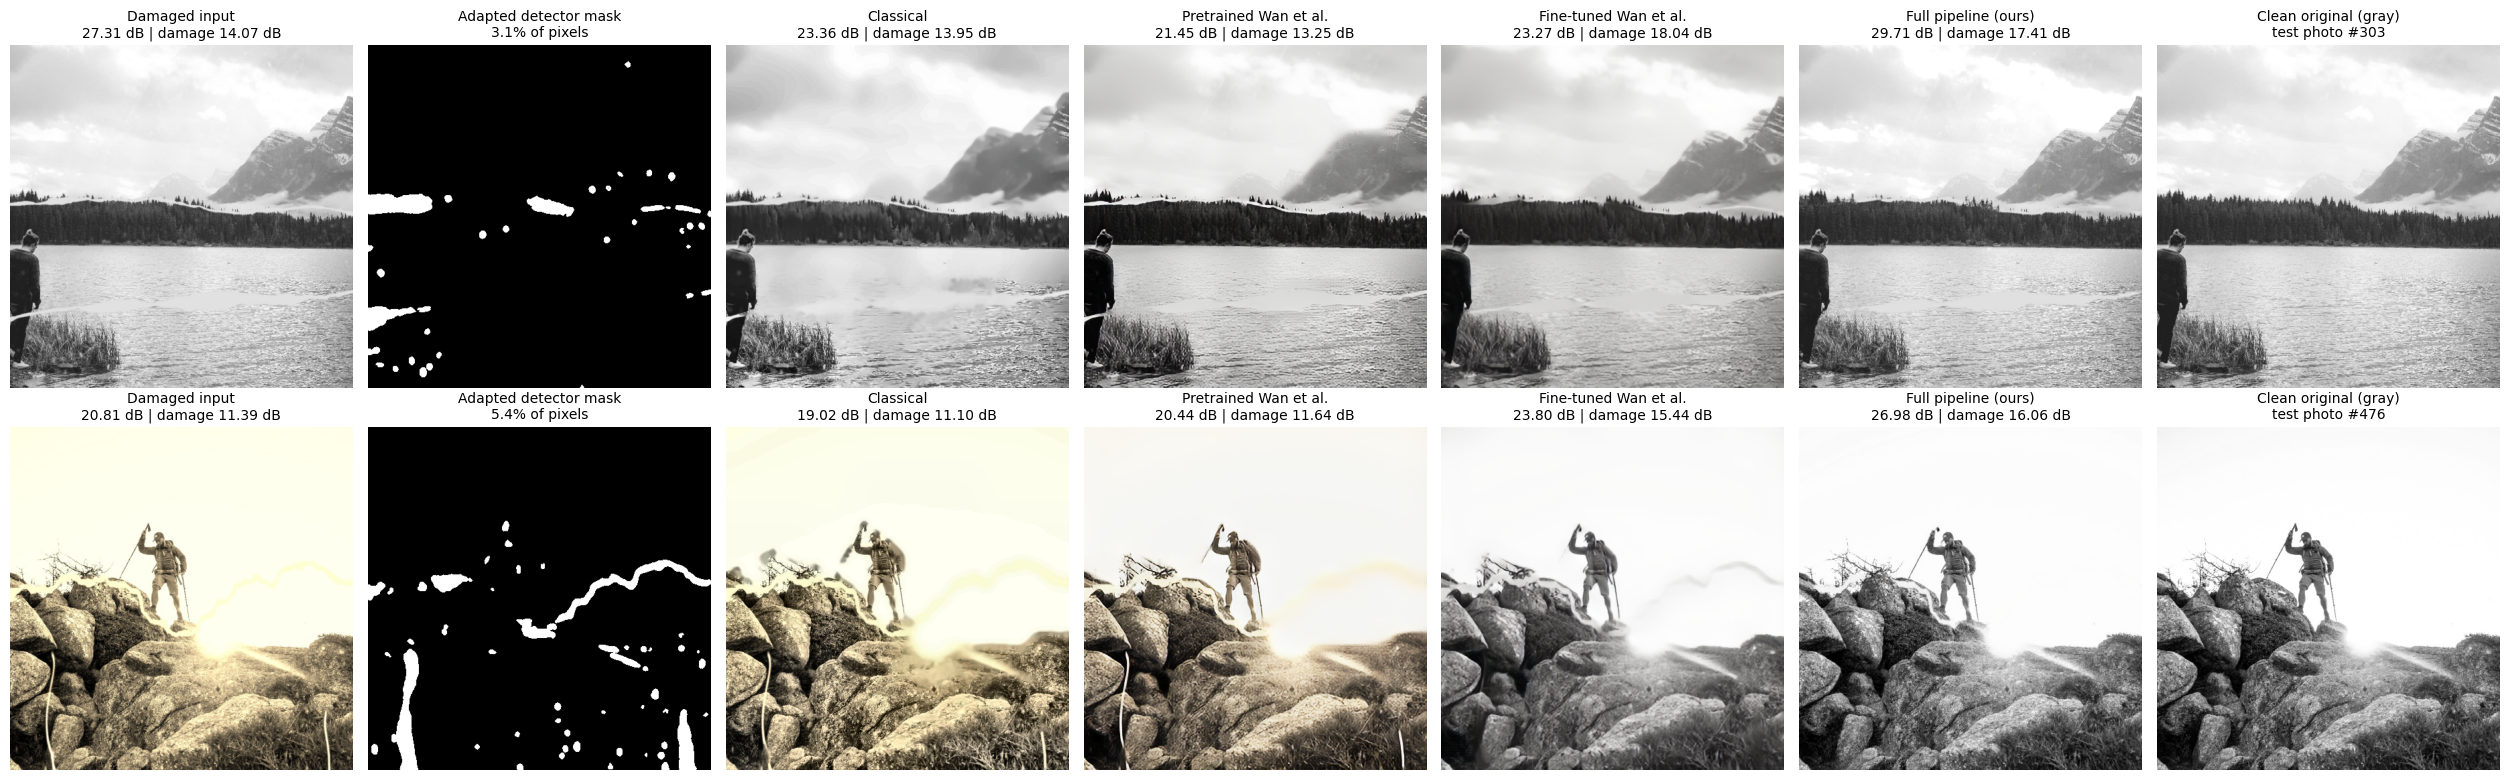

Saved to Drive: results/figures/repair_verification.png


In [19]:
# (panel title, method name); None marks panels that are not method outputs.
panels_spec = [("Damaged input", None), ("Adapted detector mask", None), ("Classical", CLASSICAL),
               ("Pretrained Wan et al.", PRETRAINED), ("Fine-tuned Wan et al.", FINETUNED),
               ("Full pipeline (ours)", FULL), ("Clean original (gray)", None)]
fig, axes = plt.subplots(len(FIG_IDX), len(panels_spec), figsize=(3.6 * len(panels_spec), 4.0 * len(FIG_IDX)))
for r, idx in enumerate(FIG_IDX):
    damaged, clean, mask = test_set.damaged[idx], test_set.pristine[idx], adapted_masks[idx]
    images = [damaged, mask] + [fig_outputs[key][idx] for _, key in panels_spec[2:-1]] + [luma_rgb_u8(clean)]
    for c, ((title, _), im) in enumerate(zip(panels_spec, images)):
        ax = axes[r, c]
        ax.imshow(im, cmap="gray", vmin=0, vmax=1) if im.ndim == 2 else ax.imshow(im)
        if c == 1:
            sub = f"{mask.mean() * 100:.1f}% of pixels"
        elif c == len(panels_spec) - 1:
            sub = f"test photo #{int(test_set.ids[idx])}"
        else:
            sub = f"{psnr_y(im, clean):.2f} dB | damage {masked_psnr_y(im, clean, ref_test[idx]):.2f} dB"
        ax.set_title(f"{title}\n{sub}", fontsize=10)
        ax.axis("off")
plt.tight_layout()
fig_path = FIG_DIR / "repair_verification.png"
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
save_to_drive(fig_path)

In [20]:
# Full pipeline on eight more test photos, drawn at random (seeded) from the whole test set.
more = np.random.default_rng(21).choice(len(test_set), 8, replace=False)
fig, axes = plt.subplots(4, 6, figsize=(19, 13.5))
for k, i in enumerate(more):
    r, c0 = k // 2, 3 * (k % 2)
    damaged, clean = test_set.damaged[i], test_set.pristine[i]
    out = pipeline.restore(damaged, adapted_masks[i])
    for c, (im, title) in enumerate([(damaged, f"Damaged #{int(test_set.ids[i])}\n{psnr_y(damaged, clean):.2f} dB"),
                                     (out, f"Full pipeline (ours)\n{psnr_y(out, clean):.2f} dB"),
                                     (luma_rgb_u8(clean), "Clean original (gray)")]):
        axes[r, c0 + c].imshow(im); axes[r, c0 + c].set_title(title, fontsize=10); axes[r, c0 + c].axis("off")
plt.tight_layout()
grid_path = FIG_DIR / "repair_pipeline_examples.png"
plt.savefig(grid_path, dpi=110, bbox_inches="tight")
plt.show()
save_to_drive(grid_path)

Output hidden; open in https://colab.research.google.com to view.

## 13. Robustness checks

Behaviour of the shipped full pipeline on four situations the application must handle:

1. **No damage detected.** Only tone correction should be applied; nothing should be inpainted.
2. **A large missing region** (a torn corner covering a quarter of the photo). The photo is still repaired, but the result is flagged as low confidence so the application can warn the user.
3. **Heavy JPEG compression.** Blocking artefacts are a kind of damage the models were not trained on; the check shows whether repair still helps.
4. **Same input twice.** The output must be identical, so results are reproducible.

In [21]:
import cv2
# All checks use the first photo from the visual comparison.
img, clean = test_set.damaged[FIG_IDX[0]], test_set.pristine[FIG_IDX[0]]
checks = []

# 1. Empty mask
out = pipeline.restore(img, np.zeros(img.shape[:2], np.uint8))
checks.append(("No damage detected", "tone correction only, no inpainting", "pass" if np.array_equal(out, tone(img)) else "FAIL"))

# 2. Top-left quarter of the photo marked as missing
torn = np.zeros(img.shape[:2], np.uint8); torn[: IMG_SIZE // 2, : IMG_SIZE // 2] = 1
out = pipeline.restore(img, torn)
ok = out.shape == img.shape and pipeline.last_info["low_confidence"] is True
checks.append((f"Large missing region ({pipeline.last_info['mask_ratio'] * 100:.0f}% masked)",
               "repaired and flagged as low confidence", "pass" if ok else "FAIL"))

# 3. Re-encode the photo as a JPEG at quality 12; the pipeline runs its own detector.
_, buf = cv2.imencode(".jpg", cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 12])
jpg = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
before, after = psnr_y(jpg, clean), psnr_y(pipeline.restore(jpg), clean)
checks.append(("Heavy JPEG compression (quality 12)", f"PSNR {before:.2f} -> {after:.2f} dB",
               "improves" if after > before else "worse: warn the user"))

# 4. Determinism
same_out = np.array_equal(pipeline.restore(img), pipeline.restore(img))
checks.append(("Same input twice", "identical output", "pass" if same_out else "FAIL"))

pd.DataFrame(checks, columns=["Situation", "Expected / observed", "Result"])

,Situation,Expected / observed,Result
0,No damage detected,"tone correction only, no inpainting",pass
1,Large missing region (25% masked),repaired and flagged as low confidence,pass
2,Heavy JPEG compression (quality 12),PSNR 24.81 -> 25.48 dB,improves
3,Same input twice,identical output,pass


## 14. Validity checks

These checks test the evaluation itself rather than the models:

1. **No leakage.** No photo, exact or near-duplicate, appears in two of the training, validation and test sets.
2. **Metrics are correct.** PSNR matches scikit-image, identical images score perfectly, and LPIPS grows with added noise.
3. **The pretrained model is Microsoft's model.** Our wrapper's output is compared with Microsoft's own `test.py` on the same photos and masks.

In [22]:
import hashlib
from skimage.metrics import peak_signal_noise_ratio as sk_psnr

# 14.1 Leakage: exact duplicates by hash, near-duplicates by 16 x 16 thumbnail similarity.
def thumbnails(a):
    # Small, mean-centred, unit-length grayscale thumbnails; their dot product is a cosine similarity.
    t = np.stack([cv2.resize(cv2.cvtColor(x, cv2.COLOR_RGB2GRAY), (16, 16), interpolation=cv2.INTER_AREA)
                  for x in a.pristine]).reshape(len(a), -1).astype(np.float32)
    t -= t.mean(1, keepdims=True)
    return t / (np.linalg.norm(t, axis=1, keepdims=True) + 1e-6)

splits = {"Training": train_set, "Validation": val_set, "Test": test_set}
hashes = {n: {hashlib.md5(x.tobytes()).hexdigest() for x in a.pristine} for n, a in splits.items()}
thumbs = {n: thumbnails(a) for n, a in splits.items()}
leak = []
for a, b in [("Training", "Test"), ("Validation", "Test"), ("Training", "Validation")]:
    sim = (thumbs[b] @ thumbs[a].T).max(1)
    leak.append({"Pair": f"{a} vs {b}", "Identical photos": len(hashes[a] & hashes[b]),
                 "Thumbnail similarity > 0.98": int((sim > 0.98).sum()), "Highest similarity": round(float(sim.max()), 3)})
display(pd.DataFrame(leak))

# 14.2 Metric sanity checks on one test photo with added Gaussian noise.
x = test_set.pristine[0]
rng_n = np.random.default_rng(0)
noisy = lambda s: np.clip(x.astype(np.float64) + rng_n.normal(0, s, x.shape), 0, 255).astype(np.uint8)
n5, n20 = noisy(5), noisy(20)
assert psnr_y(x, x) == 100.0 and abs(ssim_y(x, x) - 1.0) < 1e-9 and lpips_metric(x, x) < 1e-6
pd.DataFrame([
    ("Identical images", f"PSNR {psnr_y(x, x):.0f} (cap), SSIM {ssim_y(x, x):.4f}, LPIPS {lpips_metric(x, x):.4f}", "perfect scores"),
    ("RGB PSNR, ours vs scikit-image", f"{psnr_rgb(n5, x):.4f} vs {sk_psnr(x, n5, data_range=255):.4f}", "equal"),
    ("Luminance PSNR, ours vs scikit-image", f"{psnr_y(n5, x):.4f} vs {sk_psnr(to_luma(x), to_luma(n5), data_range=255):.4f}", "equal"),
    ("LPIPS, noise sigma 5 vs 20", f"{lpips_metric(n5, x):.4f} vs {lpips_metric(n20, x):.4f}", "increases"),
], columns=["Check", "Observed", "Expected"])

,Pair,Identical photos,Thumbnail similarity > 0.98,Highest similarity
0,Training vs Test,0,1,0.987
1,Validation vs Test,0,0,0.969
2,Training vs Validation,0,0,0.974


,Check,Observed,Expected
0,Identical images,"PSNR 100 (cap), SSIM 1.0000, LPIPS 0.0000",perfect scores
1,"RGB PSNR, ours vs scikit-image",34.2180 vs 34.2180,equal
2,"Luminance PSNR, ours vs scikit-image",37.6428 vs 37.6428,equal
3,"LPIPS, noise sigma 5 vs 20",0.0655 vs 0.5223,increases


In [23]:
# 14.3 Our wrapper vs Microsoft's own test.py, both with the published weights, on 8 test photos and their masks.
import tempfile
from PIL import Image
wan_model.mapping_net.load_state_dict(PUBLISHED_MAPPING)
chk = Path(tempfile.mkdtemp())
(chk / "in").mkdir(); (chk / "mask").mkdir()
ids = [i for i in range(len(test_set)) if test_masks[i].any()][:8]
for j, i in enumerate(ids):
    Image.fromarray(test_set.damaged[i]).save(chk / "in" / f"{j:03d}.png")
    Image.fromarray((test_masks[i] * 255).astype(np.uint8)).convert("RGB").save(chk / "mask" / f"{j:03d}.png")
# Run Microsoft's script on the saved photos and masks.
res = subprocess.run([sys.executable, "test.py", "--Scratch_and_Quality_restore", "--test_input", str(chk / "in"),
                      "--test_mask", str(chk / "mask"), "--outputs_dir", str(chk / "out"), "--gpu_ids", "0"],
                     cwd=WAN_GLOBAL, capture_output=True, text=True)
assert res.returncode == 0, res.stderr[-3000:]

ours = WanRestorer(wan_model, mode="pretrained", device=DEVICE)
agreement = []
for j, i in enumerate(ids):
    microsoft = np.asarray(Image.open(chk / "out" / "restored_image" / f"{j:03d}.png").convert("RGB"))
    mine = ours.restore(test_set.damaged[i], test_masks[i]).astype(np.float64)
    # Microsoft's test.py saves with a per-image min-max stretch; apply the same stretch before comparing.
    mine = np.clip(np.round((mine - mine.min()) / max(mine.max() - mine.min(), 1e-6) * 255), 0, 255).astype(np.uint8)
    agreement.append(psnr_rgb(mine, microsoft))
print(f"Agreement with Microsoft's test.py on {len(ids)} test photos: PSNR {min(agreement):.1f} to {max(agreement):.1f} dB "
      f"(above 50 dB means visually identical)")
load_mapping_weights(wan_model, CKPT)   # restore the fine-tuned weights

Agreement with Microsoft's test.py on 8 test photos: PSNR 52.8 to 58.4 dB (above 50 dB means visually identical)


{'seed': 123,
 'epochs': 5,
 'best_val_masked_psnr_y': 22.302030916803822,
 'base': 'microsoft/Bringing-Old-Photos-Back-to-Life v1.0 mapping_scratch'}

## 15. Where does the remaining error come from?

This section takes the full pipeline apart and compares it with two upper bounds that use the clean original, so no real method can reach them:

* **Perfect hole filling:** the clean pixels are copied into the reference damage mask of the unrepaired photo.
* **Perfect tone correction:** one tone curve per photo, fitted to the clean original, applied to the whole damaged photo.

The rows in between add the pipeline's components one at a time and swap the adapted masks for the reference masks, which shows how much a perfect detector would still add.

In [24]:
def score(fn, masks, name):
    # Whole-photo metrics plus PSNR inside the reference damage mask, for one way of repairing the test photos.
    rows = []
    for i in tqdm(range(len(test_set)), desc=name, leave=False):
        clean = test_set.pristine[i]
        out = fn(i, test_set.damaged[i], None if masks is None else masks[i])
        rows.append({"psnr_y": psnr_y(out, clean), "ssim_y": ssim_y(out, clean), "lpips_y": lpips_metric(out, clean),
                     "ref_masked": masked_psnr_y(out, clean, ref_test[i])})
    d = pd.DataFrame(rows)
    return {"Method": name, "PSNR (dB) ↑": round(d.psnr_y.mean(), 2), "SSIM ↑": round(d.ssim_y.mean(), 4),
            "LPIPS ↓": round(d.lpips_y.mean(), 4), "PSNR inside damage (dB) ↑": round(np.nanmean(d.ref_masked), 2)}

def perfect_fill(i, damaged, mask):
    # Upper bound for inpainting: the clean pixels themselves.
    out = damaged.copy(); out[mask > 0] = test_set.pristine[i][mask > 0]; return out

def perfect_tone(i, damaged, mask):
    # Upper bound for tone correction: a robust quadratic curve fitted to the clean original.
    y = np.clip(tone_fit(to_luma(damaged) / 255.0, to_luma(test_set.pristine[i]) / 255.0), 0, 1)
    return np.repeat((y * 255 + 0.5).astype(np.uint8)[..., None], 3, axis=2)

component_rows = [score(lambda i, d, m: d, None, INPUT),
                  score(lambda i, d, m: tone(d), None, "Tone correction only"),
                  score(lambda i, d, m: telea(tone(d), m), adapted_masks, "Tone + classical inpainting, adapted masks"),
                  score(lambda i, d, m: lama(tone(d), m), adapted_masks, "Tone + LaMa, adapted masks (full pipeline)"),
                  score(lambda i, d, m: lama(tone(d), m), ref_test, "Tone + LaMa, reference masks"),
                  score(perfect_fill, ref_test, "Upper bound: perfect hole filling"),
                  score(perfect_tone, None, "Upper bound: perfect tone correction")]
component_table = pd.DataFrame(component_rows).set_index("Method")
component_path = TAB_DIR / "s2_repair_components.csv"
component_table.to_csv(component_path)
save_to_drive(component_path)
component_table

Unrepaired input:   0%|          | 0/497 [00:00<?, ?it/s]

Tone correction only:   0%|          | 0/497 [00:00<?, ?it/s]

Tone + classical inpainting, adapted masks:   0%|          | 0/497 [00:00<?, ?it/s]

Tone + LaMa, adapted masks (full pipeline):   0%|          | 0/497 [00:00<?, ?it/s]

Tone + LaMa, reference masks:   0%|          | 0/497 [00:00<?, ?it/s]

Upper bound: perfect hole filling:   0%|          | 0/497 [00:00<?, ?it/s]

Upper bound: perfect tone correction:   0%|          | 0/497 [00:00<?, ?it/s]

Saved to Drive: results/tables/s2_repair_components.csv


,PSNR (dB) ↑,SSIM ↑,LPIPS ↓,PSNR inside damage (dB) ↑
Method,,,,
Unrepaired input,21.65,0.8551,0.1719,16.73
Tone correction only,27.91,0.8885,0.1556,18.66
"Tone + classical inpainting, adapted masks",28.19,0.8845,0.1454,20.39
"Tone + LaMa, adapted masks (full pipeline)",28.73,0.8862,0.1325,21.56
"Tone + LaMa, reference masks",29.44,0.8919,0.1284,21.43
Upper bound: perfect hole filling,23.26,0.8641,0.1571,100.00
Upper bound: perfect tone correction,31.85,0.9115,0.1438,19.31


### What this shows

- **Tone is the main lever and still has the most headroom.** Tone correction alone gives +6.3 dB. With a perfect tone curve the score would be 31.85 dB, about 3 dB above the current pipeline, so better colour and contrast recovery is the clearest next step.
- **The detector costs about 0.7 dB.** Running the same pipeline with the reference masks gives 29.44 dB instead of 28.73 dB. Missed thin cracks and wide tears (for example the white blob left on test photo #299) and some false positives on text and fine detail account for this.
- **Hole filling alone is not enough.** Perfectly filling the damaged pixels without fixing the tone only reaches 23.26 dB, below tone correction on its own. Both steps are needed, in that order.
- **LaMa is the right inpainter for the masks we have.** On identical masks it beats classical inpainting inside the damage (21.56 vs 20.39 dB) and on LPIPS (0.1325 vs 0.1454), at about 125 ms per photo on an L4 GPU.

## 16. Conclusions

1. **The repair stage works.** The final pipeline (OpenPhoto-adapted detector, colour-aware tone correction, LaMa inpainting) improves the test photos by +7.1 dB PSNR (95% CI 6.4 to 7.7) and lowers LPIPS from 0.172 to 0.133. Scratches, cracks and tears are removed in the verification figures and the photo outside the mask is left untouched.
2. **The detector needed retraining for this dataset.** Sai's notebook-02 U-Net was trained on a different kind of damage and finds almost none of OpenPhoto's. Fine-tuning a copy of it on OpenPhoto, saved separately as `damage_detection_unet_openphoto.pt`, raises damage recall from 0.04 to 0.78. Notebook 02 and its checkpoint are unchanged.
3. **Fine-tuning Wan et al. (2020) is a useful baseline but not the final method.** It gains about 2 dB over the published weights and is stable across seeds, but whole-region repainting limits it on this data.
4. **Limitations.** The output is grayscale, so colour is not restored. Some wide tears are only partly filled, and the detector occasionally repaints fine detail such as lettering. Thresholds and model choices were made on the validation split only; the test split was used once for the numbers above. One training and test pair has a near-duplicate thumbnail (similarity above 0.98), which has a negligible effect on a 497-photo average.
5. **Next steps.** Improve tone recovery, which has about 3 dB of headroom, and improve detection of wide tears, which is worth up to 0.7 dB.